# Gasto público en pensiones y pobreza infantil

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "gasto-pensiones-pobreza-infantil"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público en pensiones y pobreza infantil"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Gasto público en pensiones", "unidad": "% del PIB"}
EJE_Y = {"titulo": "Menores de 18 años en pobreza relativa", "unidad": "% de la población menor de 18 años"}
EDAD_Y = "Y_LT18"  # tramo de edad del eje y en la base de distribución de la renta de la OCDE
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes el mismo año.

- **Eje horizontal:** el **gasto público en pensiones** de jubilación y supervivencia en porcentaje del PIB (el mismo indicador que `gasto-pensiones-pib`).
- **Eje vertical:** el porcentaje de los **menores de 18 años en pobreza relativa**: los que viven en hogares con una renta disponible, ajustada por el tamaño del hogar, inferior a la mitad de la mediana de su país (el umbral habitual de la OCDE, el mismo de `gasto-pensiones-pobreza-mayores`).

**Para qué sirve.** Es el argumento de quienes sostienen que el gasto en pensiones deja menos recursos para otras prestaciones y para las generaciones jóvenes (equidad entre generaciones). Su pareja es `gasto-pensiones-pobreza-mayores`, con el argumento de quienes defienden subir o mantener las pensiones. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El gasto en porcentaje del PIB depende también de cuántas personas mayores hay en cada país, no solo de cuánto cobra cada una.
- La pobreza infantil depende sobre todo del empleo y los salarios de los padres, de la composición del hogar y de las prestaciones por hijo y otras ayudas, no solo de lo que se gasta en pensiones.
- El umbral es relativo a la mediana de cada país: no compara niveles de vida entre países.
- Cada país usa su propia encuesta de ingresos, armonizada por la OCDE.

## 2. Descarga

- **Eje x:** OCDE, base de gasto social (SOCX, `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0`), gasto público (`ES10`) en prestaciones en dinero (`C`) de vejez y supervivencia (`TP01`), en % del PIB, para los países de la OCDE y la media `OECD`.
- **Eje y:** OCDE, base de distribución de la renta (IDD, `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0`), tasa de pobreza con la renta disponible (`PR_INC_DISP`), umbral del 50 % de la mediana (`PL_50`), definición de renta vigente (`METH2012`, `D_CUR`), población menor de 18 años (`Y_LT18`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta

AREAS = {c: c for c in [*PAISES, "OECD"]}  # países del universo y la media, con su código como clave de serie
HOY = date.today().isoformat()

# SOCX: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.EXPEND_SOURCE.SPENDING_TYPE.PROGRAMME_TYPE.PRICE_BASE
DATAFLOW_SOCX = "OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0"
CLAVE_SOCX = "{AREA}.A.SOCX.PT_B1GQ.ES10.C.TP01._Z"
# IDD: REF_AREA.FREQ.MEASURE.STATISTICAL_OPERATION.UNIT_MEASURE.AGE.METHODOLOGY.DEFINITION.POVERTY_LINE
DATAFLOW_IDD = "OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0"
CLAVE_IDD = f"{{AREA}}.A.PR_INC_DISP._Z.PT_POP.{EDAD_Y}.METH2012.D_CUR.PL_50"

x, _ = oecd.get(DATAFLOW_SOCX, CLAVE_SOCX, areas=AREAS, desde=DESDE)
y, _ = oecd.get(DATAFLOW_IDD, CLAVE_IDD, areas=AREAS, desde=DESDE)
print("Con gasto en pensiones:", x["serie"].nunique(), "· con tasa de pobreza:", y["serie"].nunique())
print("Media OCDE en el eje y:", "OECD" in set(y["serie"]))

Con gasto en pensiones: 39 · con tasa de pobreza: 37
Media OCDE en el eje y: False


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE.
2. **Media de la OCDE:** SOCX publica la media de la OCDE, pero la IDD no; el escritor solo la añade como punto si tiene dato en los dos ejes el mismo año.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

### Notas

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


_, FLUJO_SOCX, VER_SOCX = DATAFLOW_SOCX.split(",")
_, FLUJO_IDD, VER_IDD = DATAFLOW_IDD.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_SOCX} (SOCX, versión {VER_SOCX}): TP01, ES10, C, PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_IDD} (IDD, versión {VER_IDD}): PR_INC_DISP, {EDAD_Y}, METH2012, D_CUR, PL_50", oecd.URL_EXPLORER, HOY),
]
NOTAS = [
    "Gasto en pensiones: OCDE, base de gasto social (SOCX), gasto público en prestaciones en dinero de vejez y "
    "supervivencia (TP01, ES10, C), en % del PIB; incluye las pensiones de todas las administraciones públicas y no "
    "las de incapacidad.",
    "Pobreza infantil: OCDE, base de distribución de la renta (IDD), porcentaje de los menores de 18 años en hogares "
    "con una renta disponible equivalente inferior al 50 % de la mediana nacional (definición de renta vigente desde "
    "2012); el mismo umbral que en la gráfica de la pobreza de las personas mayores.",
    "La IDD no publica la media de la OCDE: no hay punto de la media.",
    "El gasto en % del PIB depende también de cuántas personas mayores hay en cada país, y la pobreza infantil, sobre "
    "todo del empleo de los padres y de las prestaciones por hijo, no solo del gasto en pensiones.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

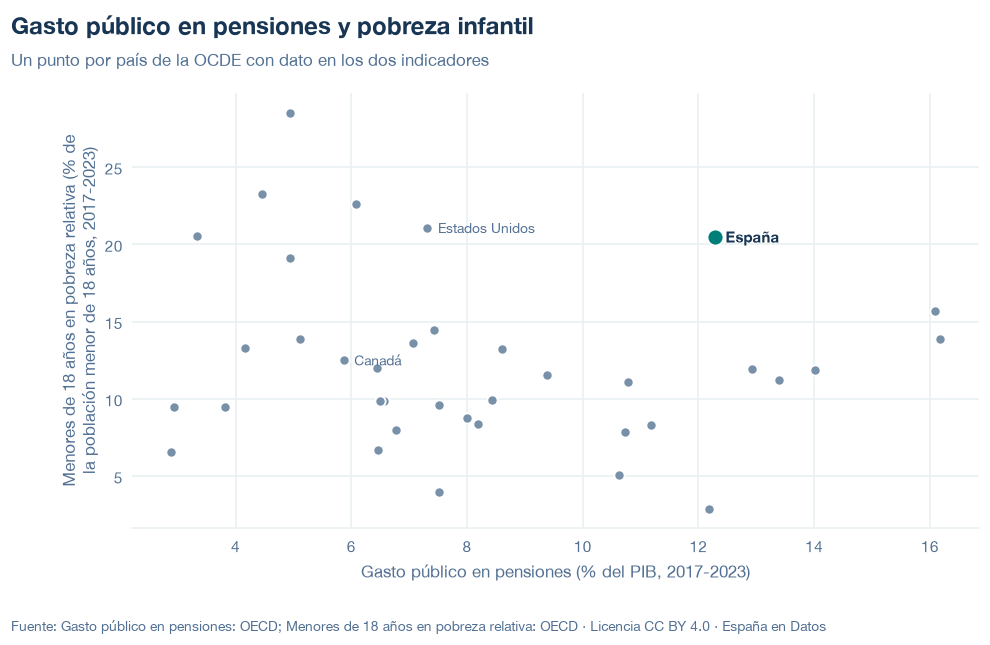

codigo  anio      x         y
   AUS  2020  4.160 13.300000
   AUT  2021 14.017 11.888030
   BEL  2021 10.724  7.874426
   CAN  2022  5.867 12.500000
   CHE  2021  6.558  9.840459
   CHL  2022  3.328 20.526937
   CRI  2022  4.939 28.534284
   CZE  2021  8.191  8.398939
   DEU  2021 10.791 11.100000
   DNK  2021  7.513  4.000000
   ESP  2021 12.282 20.499499
   EST  2021  6.778  8.005596
   FIN  2021 12.176  2.900000
   FRA  2022 13.396 11.200000
   GBR  2022  7.072 13.644376
   GRC  2021 16.183 13.902960
   HUN  2017  8.431  9.903518
   IRL  2021  2.933  9.503103
   ISL  2019  2.876  6.533986
   ISR  2023  4.464 23.241842
   ITA  2021 16.089 15.678507
   JPN  2021  9.379 11.537073
   KOR  2022  3.810  9.500000
   LTU  2021  6.498  9.868029
   LUX  2021  8.611 13.221602
   LVA  2021  7.519  9.634773
   MEX  2022  4.943 19.105087
   NLD  2021  6.444 12.000000
   NOR  2021  6.463  6.720000
   NZL  2022  5.121 13.900000
   POL  2021 11.187  8.287168
   PRT  2021 12.919 11.954268
   SVK  20

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-pensiones-pobreza-infantil.json y data/gasto-pensiones-pobreza-infantil.csv


## 6. Fuentes, notas y licencia

- OCDE, SOCX: `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0` (`TP01`, `ES10`, `C`, `PT_B1GQ`).
- OCDE, IDD: `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0` (`PR_INC_DISP`, `Y_LT18`, `METH2012`, `D_CUR`, `PL_50`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.